# Proyecto tutorial K-Medias: California Housing

## 1. Configuracion del entorno

Este notebook reutiliza las funciones de `app.py` para mantener una sola implementacion reproducible. La semilla es 42.

## 2. Carga y comprension del dataset

California Housing contiene 20.640 grupos de bloques censales del censo de 1990, no viviendas individuales. Usamos solo `Latitude`, `Longitude` y `MedInc`; esta ultima expresa el ingreso mediano en decenas de miles de USD de 1990. No utilizamos el precio.

Se carga `housing.csv` de la raiz o de `data/raw`; si no existe se descarga con scikit-learn. Las filas duplicadas en solo estas tres variables se conservan: no demuestran que el bloque censal sea el mismo. Los datos no numericos, nulos e infinitos se rechazan explicitamente.

In [1]:
from pathlib import Path
import sys
import time

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.model_selection import train_test_split

ROOT = Path.cwd() if (Path.cwd() / "src/app.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from app import FEATURES, SEED, load_data, fit_models, save_results

np.random.seed(SEED)
data = load_data()
display(data.head())
display(data.dtypes.rename("tipo"))
display(data.describe())
display(data.isna().sum().rename("nulos"))
display(data.corr())
print("Duplicados en variables seleccionadas:", data.duplicated().sum())

,Latitude,Longitude,MedInc
row_id,,,
0,37.88,-122.23,8.3252
1,37.86,-122.22,8.3014
2,37.85,-122.24,7.2574
3,37.85,-122.25,5.6431
4,37.85,-122.25,3.8462


Latitude     float64
Longitude    float64
MedInc       float64
Name: tipo, dtype: object

,Latitude,Longitude,MedInc
count,20640.000000,20640.000000,20640.000000
mean,35.631861,-119.569704,3.870671
std,2.135952,2.003532,1.899822
min,32.540000,-124.350000,0.499900
25%,33.930000,-121.800000,2.563400
50%,34.260000,-118.490000,3.534800
75%,37.710000,-118.010000,4.743250
max,41.950000,-114.310000,15.000100


Latitude     0
Longitude    0
MedInc       0
Name: nulos, dtype: int64

,Latitude,Longitude,MedInc
Latitude,1.000000,-0.924664,-0.079809
Longitude,-0.924664,1.000000,-0.015176
MedInc,-0.079809,-0.015176,1.000000


Duplicados en variables seleccionadas: 5


## 3. Division de entrenamiento y prueba

Separamos 80/20 antes de ajustar cualquier transformacion. El conjunto test no se usa para seleccionar hiperparametros.

## 4. Escalado de las variables

K-Means minimiza distancias euclideas: estandarizar evita que la escala del ingreso o de las coordenadas domine arbitrariamente. `fit_models` ajusta `StandardScaler` solo sobre train dentro de un `Pipeline`. El mismo escalador transforma test sin reajustarse.

## 5. K-Means con seis clusters

`KMeans(n_clusters=6, n_init=20, random_state=42)` se ajusta con train escalado. El seis viene del enunciado, no de una busqueda del k optimo. La inercia depende de escala, cantidad de puntos y k; no mide por si sola calidad absoluta.

## 6. Asignacion de clusters a train

Convertimos los identificadores 0 a 5 a categorias nominales. Sus numeros no representan un orden de riqueza o calidad.

In [2]:
train, test = train_test_split(data, test_size=0.2, random_state=SEED)
assert set(train.index).isdisjoint(test.index)
started = time.perf_counter()
clustering, search = fit_models(train)
print(f"Tiempo K-Means y busqueda del arbol: {time.perf_counter() - started:.2f} s")
np.testing.assert_allclose(clustering.named_steps["scaler"].mean_, train.mean())
assert clustering.named_steps["scaler"].n_samples_seen_ == len(train)
train_labeled = train.assign(
    cluster=pd.Categorical(clustering.predict(train), categories=range(6))
)
print(f"Train: {len(train)}; test: {len(test)}")
print("Inercia train:", clustering.named_steps["kmeans"].inertia_)
display(train_labeled.head())
display(train_labeled["cluster"].value_counts().sort_index())

Tiempo K-Means y busqueda del arbol: 1.04 s
Train: 16512; test: 4128
Inercia train: 8069.1396394366675


,Latitude,Longitude,MedInc,cluster
row_id,,,,
14196,32.71,-117.03,3.2596,1
8267,33.77,-118.16,3.8125,1
17445,34.66,-120.48,4.1563,4
14265,32.69,-117.11,1.9425,1
2271,36.78,-119.80,3.5542,4


cluster
0     453
1    5189
2    2244
3    3379
4    1321
5    3926
Name: count, dtype: int64

## 7. Visualizacion de train

El panel izquierdo muestra longitud frente a latitud, coloreadas por cluster. La distribucion de ingresos por grupo permite estudiar la tercera dimension: los colores pueden solaparse geograficamente porque tambien interviene `MedInc`.

## 8. Prediccion de clusters sobre test

`clustering.predict(test)` aplica el escalador ya entrenado y asigna cada punto al centro mas cercano. No ejecutamos otro `fit` ni otro K-Means sobre test.

## 9. Comparacion visual train y test

El panel derecho superpone test con triangulos sobre train. Los colores tienen exactamente el mismo significado en ambos conjuntos. Los centros son proyecciones de centroides tridimensionales, no centros administrativos. Los grados tampoco equivalen a distancias geodesicas.

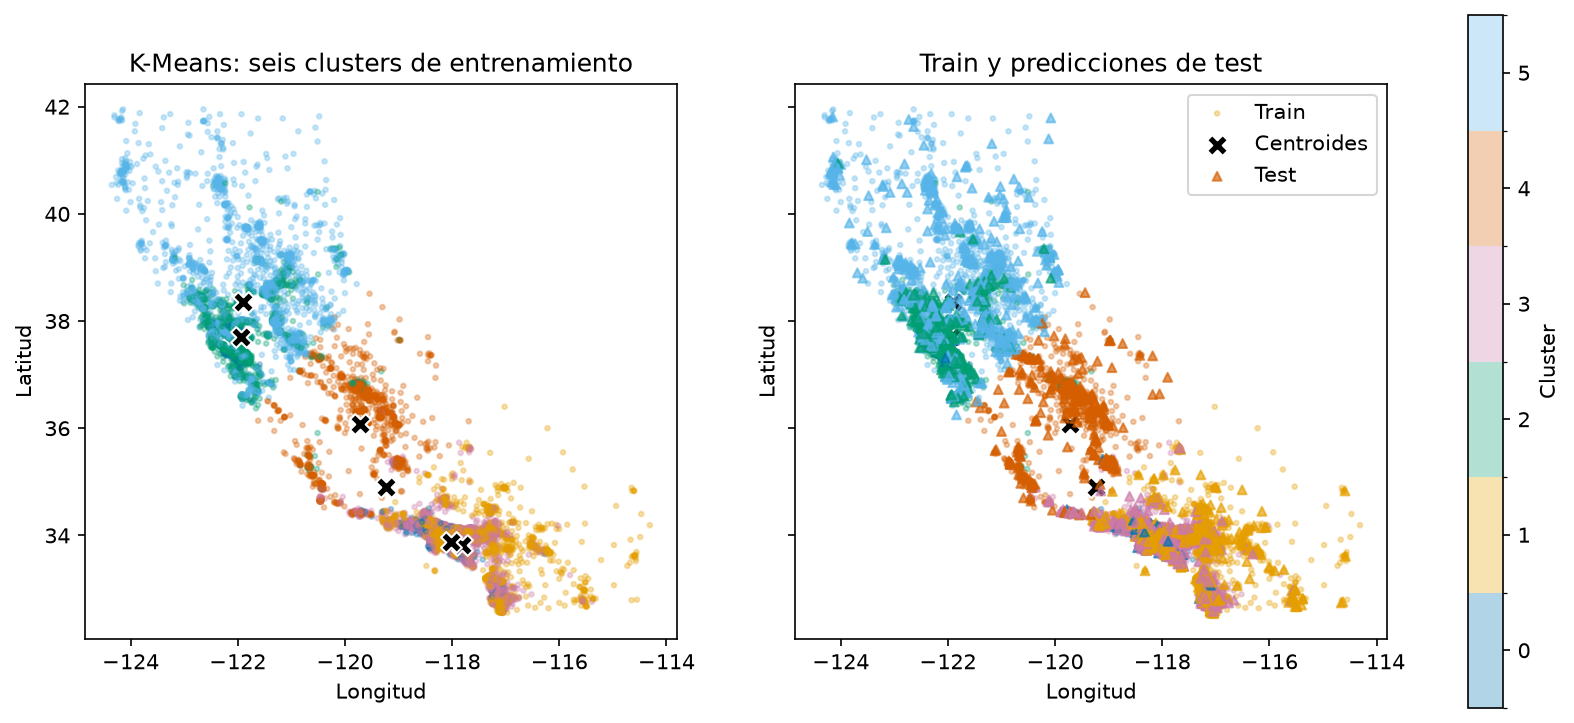

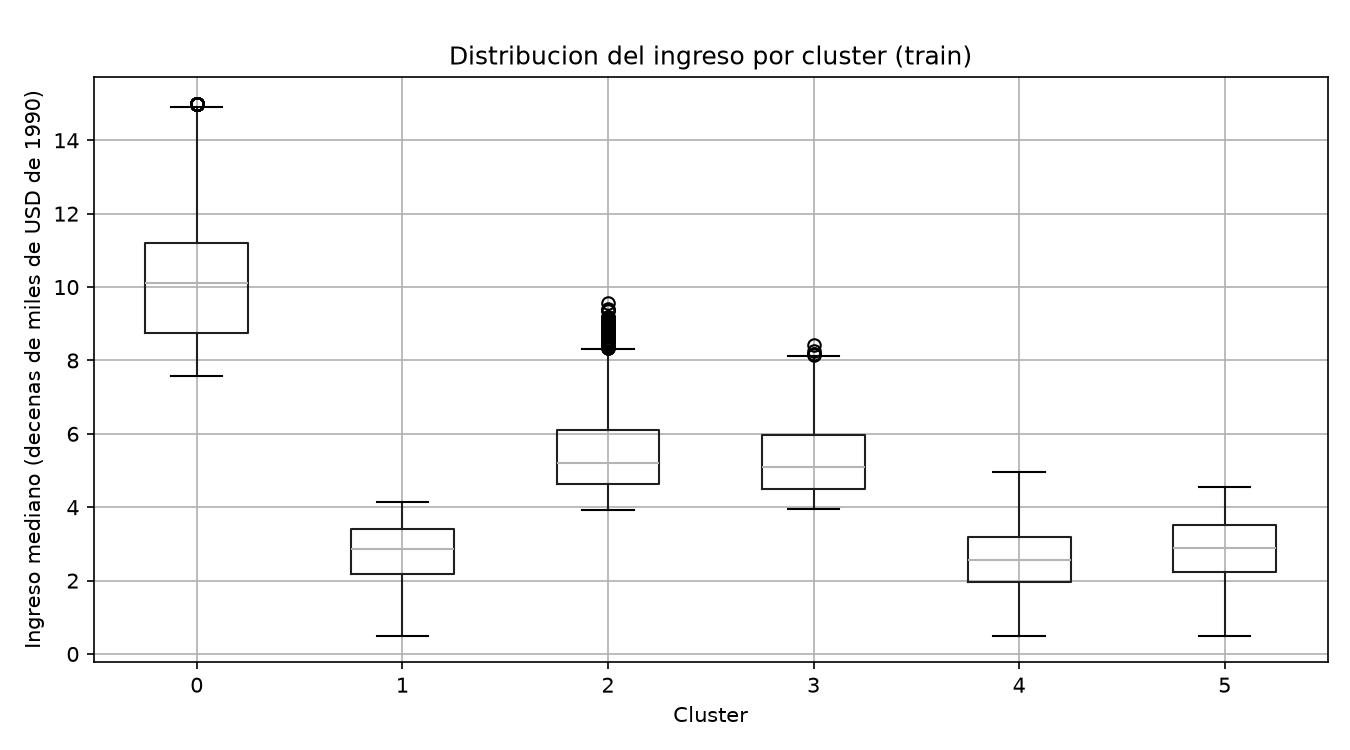

,cluster,count,latitude_mean,longitude_mean,income_mean,income_median
0,0,453,34.900552,-119.237020,10.443602,10.12410
1,1,5189,33.816575,-117.816824,2.781013,2.84780
2,2,2244,37.701390,-121.939661,5.515039,5.21605
3,3,3379,33.867772,-118.024111,5.312157,5.10480
4,4,1321,36.081628,-119.727593,2.625024,2.55560
5,5,3926,38.347063,-121.900329,2.833470,2.88360


,cluster,Latitude,Longitude,MedInc
0,0,34.894703,-119.229033,10.433953
1,1,33.816671,-117.816468,2.778591
2,2,37.701351,-121.939358,5.516285
3,3,33.867650,-118.024399,5.306654
4,4,36.081628,-119.727593,2.625024
5,5,38.346757,-121.900522,2.834124


In [3]:
test_labeled = test.assign(
    cluster=pd.Categorical(clustering.predict(test), categories=range(6))
)
metrics = save_results(data, train, test, clustering, search, ROOT)
display(Image(filename=str(ROOT / "reports/clusters.png")))
display(Image(filename=str(ROOT / "reports/income_by_cluster.png")))
display(pd.read_csv(ROOT / "reports/cluster_profiles.csv"))
display(pd.read_csv(ROOT / "reports/cluster_centers.csv"))

## 10. Preparacion de pseudoetiquetas

Las variables predictoras son las tres columnas originales; el objetivo son las categorias que K-Means asigno a train. La columna `cluster` nunca entra como predictor.

## 11. Clasificador supervisado

`fit_models(train)` ya entreno un arbol de decision: es interpretable y aproxima regiones mediante cortes de las variables. Sus fronteras alineadas con los ejes aproximan las fronteras oblicuas de K-Means. Se comparan nueve combinaciones de `max_depth` (6, 10, sin limite) y `min_samples_leaf` (1, 5, 10), con CV estratificada de tres folds y F1 macro. Test no participa en la seleccion.

Las pseudoetiquetas de CV proceden del agrupador ajustado con todo train: esta CV mide imitacion de ese agrupador fijo, no validacion del proceso completo de clustering.

## 12. Evaluacion en test

Comparamos contra las etiquetas de K-Means en test, no contra etiquetas reales. Incluimos accuracy, precision, recall, F1 por clase, F1 macro, matriz de confusion y un baseline de clase mayoritaria. La silueta mide separacion de clusters, no exactitud del clasificador.

Mejores parametros: {'max_depth': 10, 'min_samples_leaf': 1}


,params,mean_test_score,std_test_score,rank_test_score
3,"{'max_depth': 10, 'min_samples_leaf': 1}",0.988437,0.000944,1
6,"{'max_depth': None, 'min_samples_leaf': 1}",0.988362,0.001221,2
7,"{'max_depth': None, 'min_samples_leaf': 5}",0.984667,0.002048,3
4,"{'max_depth': 10, 'min_samples_leaf': 5}",0.984462,0.002248,4
0,"{'max_depth': 6, 'min_samples_leaf': 1}",0.981826,0.001689,5
5,"{'max_depth': 10, 'min_samples_leaf': 10}",0.981492,0.003457,6
8,"{'max_depth': None, 'min_samples_leaf': 10}",0.981492,0.003457,6
1,"{'max_depth': 6, 'min_samples_leaf': 5}",0.981277,0.002009,8
2,"{'max_depth': 6, 'min_samples_leaf': 10}",0.979665,0.003477,9


train_accuracy            0.999516
test_accuracy             0.994428
test_f1_macro             0.990578
baseline_test_accuracy    0.333091
train_silhouette          0.400553
test_silhouette           0.398106
dtype: float64

,precision,recall,f1-score,support
0,0.990826,0.964286,0.977376,112.000000
1,0.997097,0.999273,0.998184,1375.000000
2,0.990366,0.998058,0.994197,515.000000
3,0.992762,0.993961,0.993361,828.000000
4,0.993958,0.976261,0.985030,337.000000
5,0.994802,0.995838,0.995320,961.000000
accuracy,0.994428,0.994428,0.994428,0.994428
macro avg,0.993302,0.987946,0.990578,4128.000000
weighted avg,0.994427,0.994428,0.994414,4128.000000


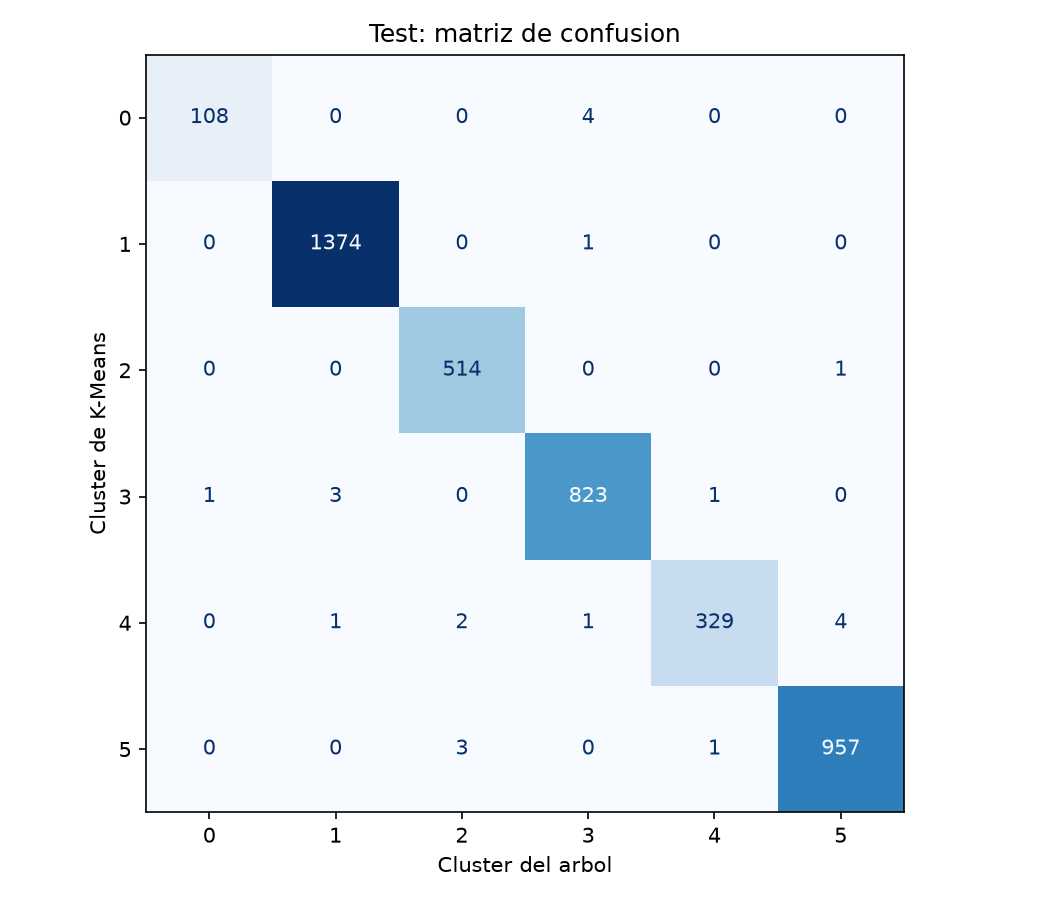

In [4]:
print("Mejores parametros:", search.best_params_)
display(pd.DataFrame(search.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score"))
display(pd.Series({key: metrics[key] for key in [
    "train_accuracy", "test_accuracy", "test_f1_macro", "baseline_test_accuracy",
    "train_silhouette", "test_silhouette",
]}))
display(pd.DataFrame(metrics["classification_report"]).T)
display(Image(filename=str(ROOT / "reports/confusion_matrix.png")))

## 13. Persistencia e inferencia posterior

`save_results` guarda `models/kmeans_pipeline.joblib` (escalador y K-Means juntos) y `models/decision_tree.joblib` (arbol sobre variables originales). Ambos se guardan entrenados solo con train. El pipeline evita olvidar el escalado al predecir. Solo se deben cargar archivos joblib de confianza y con versiones de dependencias compatibles.

Comprobamos que los modelos recargados mantienen las mismas predicciones y probamos dos puntos nuevos. Finalmente mostramos el informe calculado a partir de esta ejecucion.

In [5]:
restored_kmeans = joblib.load(ROOT / "models/kmeans_pipeline.joblib")
restored_tree = joblib.load(ROOT / "models/decision_tree.joblib")
np.testing.assert_array_equal(restored_kmeans.predict(test), clustering.predict(test))
np.testing.assert_array_equal(restored_tree.predict(test), search.predict(test))
new_points = pd.DataFrame({
    "Latitude": [34.05, 37.77],
    "Longitude": [-118.24, -122.42],
    "MedInc": [4.0, 6.0],
})[FEATURES]
display(new_points.assign(
    cluster_kmeans=restored_kmeans.predict(new_points),
    cluster_tree=restored_tree.predict(new_points),
))
display(Markdown((ROOT / "reports/analysis.md").read_text(encoding="utf-8")))

,Latitude,Longitude,MedInc,cluster_kmeans,cluster_tree
0,34.05,-118.24,4.0,1,1
1,37.77,-122.42,6.0,2,2


# Resultados: agrupacion de California Housing

## Datos y protocolo

Se analizaron 20,640 grupos de bloques censales, no viviendas individuales.
Variables: Latitude, Longitude y MedInc. No se utiliza el precio como predictor.
MedInc expresa el ingreso mediano en decenas de miles de dolares de 1990.
Valores nulos en estas variables: 0.
Filas duplicadas en estas tres variables: 5; se conservan,
pues no demuestran que sean el mismo bloque censal.
Particion aleatoria 80/20, semilla 42: 16,512 train y 4,128 test.
StandardScaler y K-Means se ajustaron exclusivamente con train.
Se fijo k=6 por el enunciado; no se afirma que sea el numero optimo.

## Interpretacion de los clusters

El mapa muestra separacion geografica, pero no toda la informacion: el ingreso
es la tercera dimension y por eso pueden solaparse colores en latitud/longitud.
Cada variable tiene el mismo peso tras estandarizar; los grados no son distancias
geodesicas. Los centroides del mapa son proyecciones de centros tridimensionales.
El cluster 5 tiene la latitud media mas alta y el 1 la mas baja.
El cluster 0 tiene el ingreso medio mas alto:
10.44 decenas de miles de USD.
Los perfiles completos y tamanos estan en cluster_profiles.csv; las etiquetas
0 a 5 son categorias nominales, no un ranking de calidad ni de ingreso.

Silhouette train (muestra de hasta 2000): 0.40055299144426537.
Silhouette test (muestra de hasta 2000): 0.3981055303918927.
Esta medida va de -1 a 1: mayor implica grupos mas compactos y separados.
La superposicion de test permite inspeccionar continuidad espacial, pero no
demuestra que los grupos representen regiones administrativas reales.

## Clasificacion supervisada

Se eligio un arbol de decision por su interpretabilidad y por poder separar
regiones no lineales combinando las tres variables. Sus cortes alineados con los
ejes solo aproximan las fronteras oblicuas de los grupos de K-Means.
Se compararon nueve configuraciones mediante CV estratificada de tres folds
solo en train, con F1 macro. Las pseudoetiquetas se fijaron antes de esta CV;
la puntuacion CV evalua la imitacion del agrupador, no todo el proceso de clustering.
Mejores parametros: {'max_depth': 10, 'min_samples_leaf': 1}.
F1 macro CV: 0.9884.
Accuracy train: 0.9995.
Accuracy test: 0.9944.
F1 macro test: 0.9906.
Accuracy del baseline mayoritario en test: 0.3331.
Brecha accuracy train-test: 0.0051.
Precision, recall, F1 y soporte por clase estan en metrics.json.

Estas cifras miden concordancia con K-Means, no exactitud frente a etiquetas
reales. Un resultado alto indica que el arbol reproduce bien esa particion.
No se puede concluir capacidad de predecir precios o clases socioeconomicas.
La division aleatoria puede compartir vecindarios entre train y test; para
generalizar a regiones nuevas se necesitaria una evaluacion espacial por bloques.
K-Means ya permite predecir directamente; el arbol aporta una aproximacion
interpretable, no nuevas etiquetas independientes.

## Modelos

models/kmeans_pipeline.joblib incluye el escalador y el agrupador.
models/decision_tree.joblib recibe Latitude, Longitude y MedInc sin escalar.
Ambos se guardan sin reajustar con test. Cargar solo archivos joblib de confianza.
